In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

: 

In [ ]:
df=pd.read_csv('data.csv')
df.head(1)

,Town,Country,Store ID,Manager name,Staff,Floor Space,Window,Car park,Demographic score,Location,40min population,30 min population,20 min population,10 min population,Store age,Clearance space,Competition number,Competition score,Performance
0,Skipton,UK,2039,Valentina,-2,12288,105,No,12,Retail Park,1595638,1281661,1104490,1011395,11,219,13,18,Bad


: 

In [ ]:
df.drop(['Store ID','Manager name'],axis=1,inplace=True)
# df.head(3)

: 

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Town                274 non-null    object
 1   Country             274 non-null    object
 2   Staff               274 non-null    int64 
 3   Floor Space         274 non-null    int64 
 4   Window              274 non-null    int64 
 5   Car park            274 non-null    object
 6   Demographic score   274 non-null    int64 
 7   Location            274 non-null    object
 8   40min population    274 non-null    int64 
 9   30 min population   274 non-null    int64 
 10  20 min population   274 non-null    int64 
 11  10 min population   274 non-null    int64 
 12  Store age           274 non-null    int64 
 13  Clearance space     274 non-null    int64 
 14  Competition number  274 non-null    int64 
 15  Competition score   274 non-null    int64 
 16  Performance         274 no

: 

In [ ]:
df.isna().sum()

Town                  0
Country               0
Staff                 0
Floor Space           0
Window                0
Car park              0
Demographic score     0
Location              0
40min population      0
30 min population     0
20 min population     0
10 min population     0
Store age             0
Clearance space       0
Competition number    0
Competition score     0
Performance           0
dtype: int64

: 

c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level 

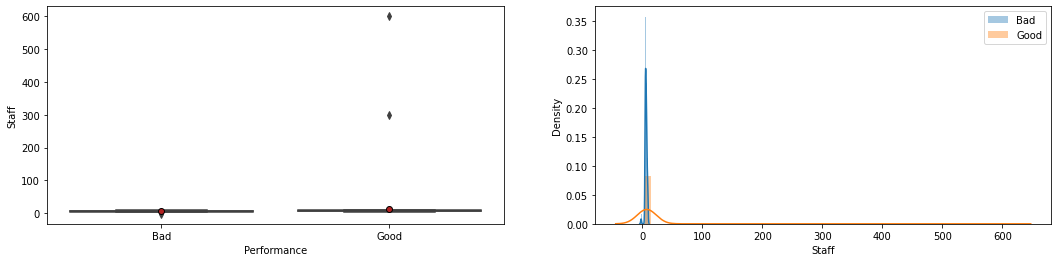

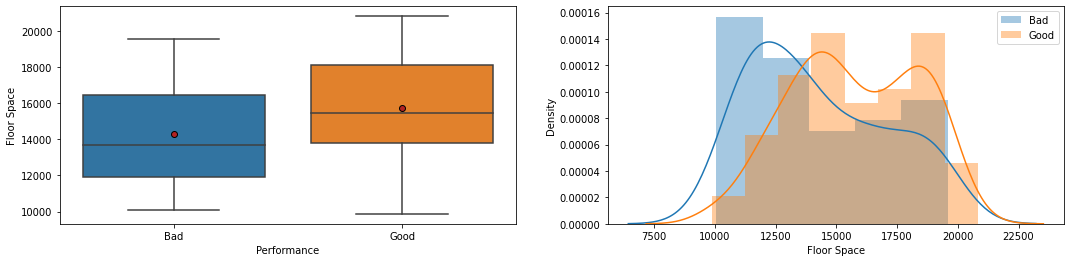

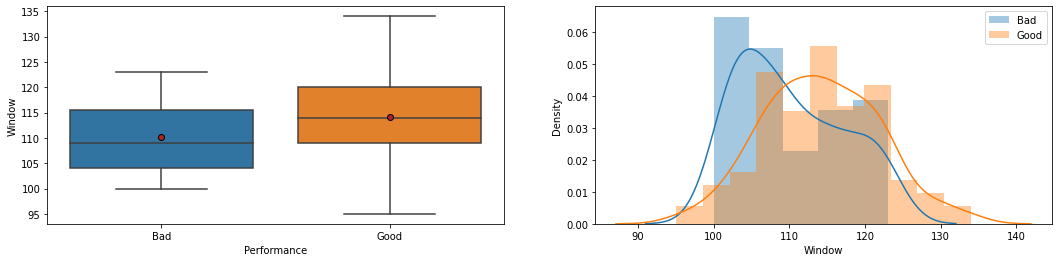

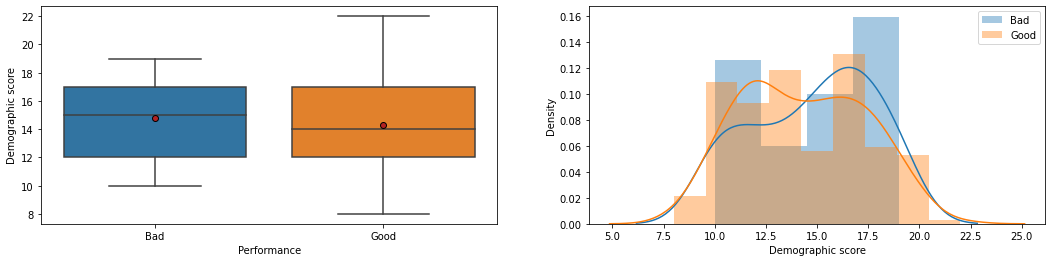

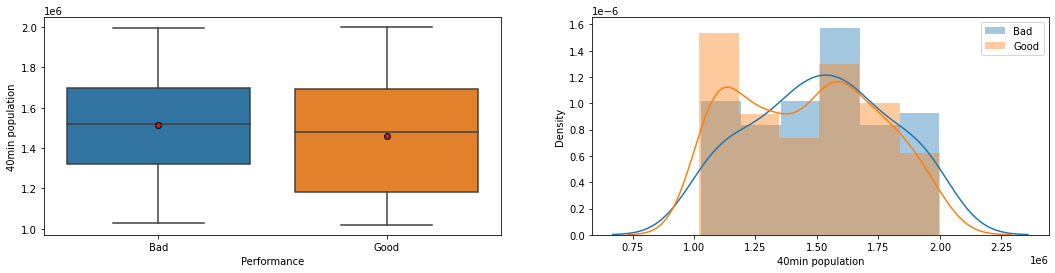

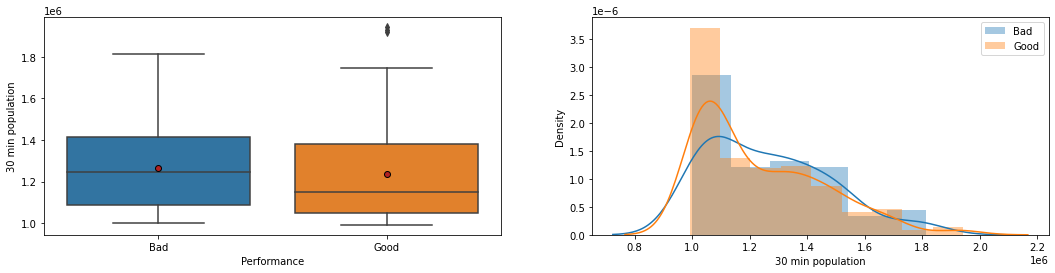

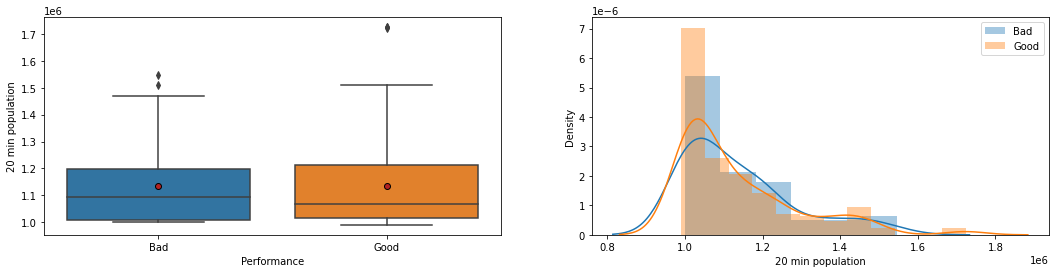

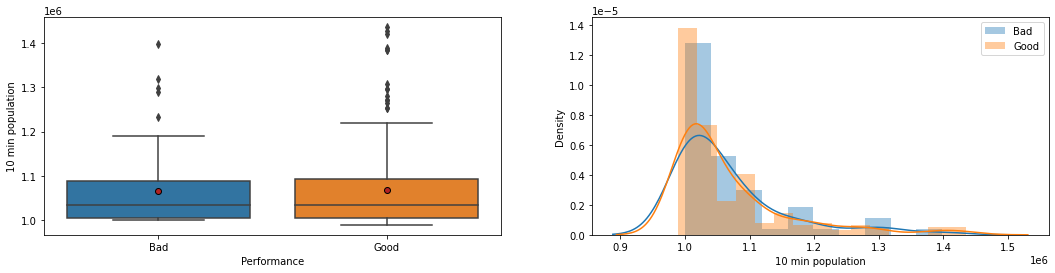

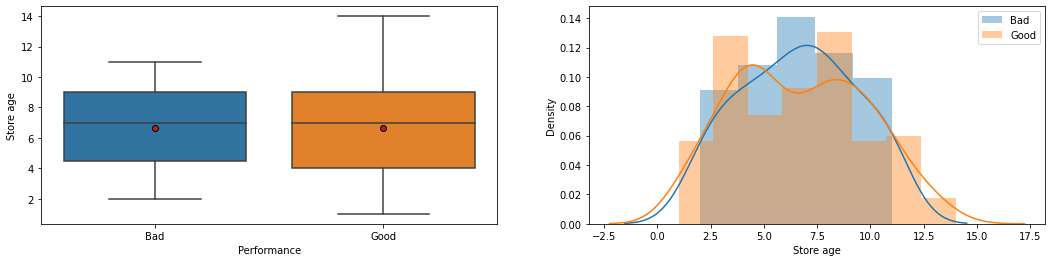

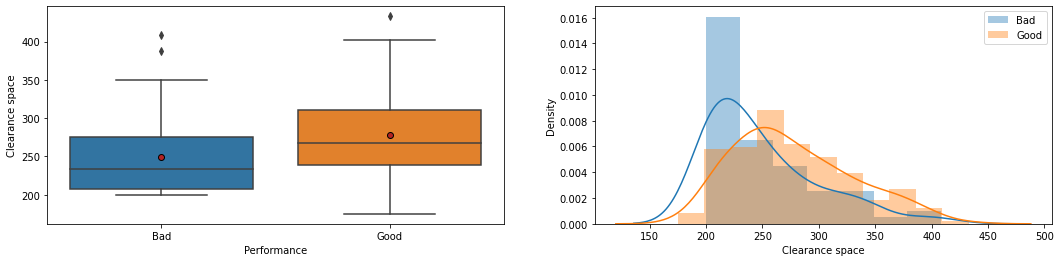

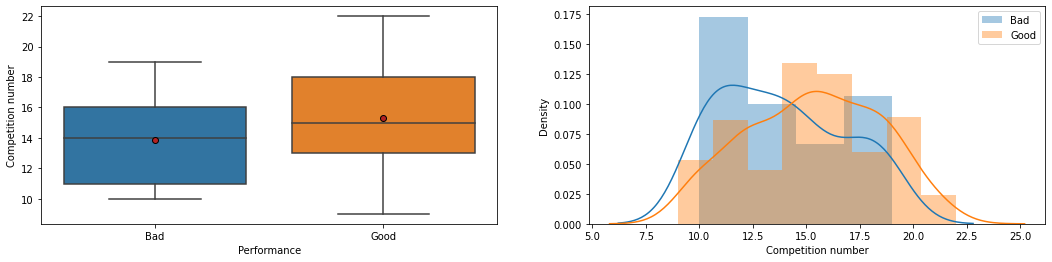

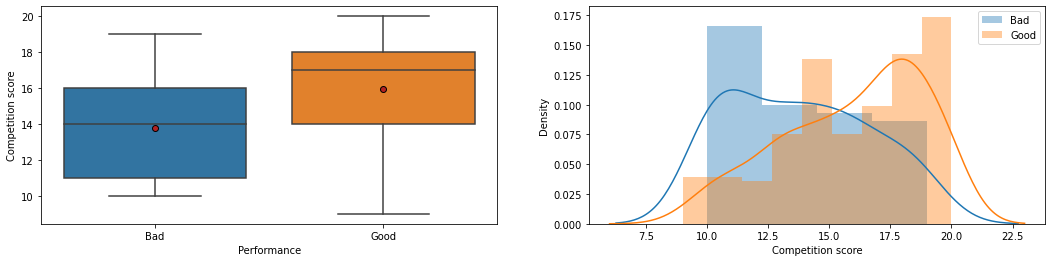

: 

In [ ]:
for col in df.columns:
    if df[col].dtype==np.dtype('int64'):
        plt.figure(figsize=(18,4))
        plt.subplot(1,2,1)
        meanprops = {'marker':'o', 'markeredgecolor':'black','markerfacecolor':'firebrick'}
        sns.boxplot(x='Performance',y=col,data=df,showmeans=True, meanprops=meanprops)
        plt.subplot(1,2,2)
        sns.distplot(df[df['Performance']=='Bad'][col],label='Bad')
        sns.distplot(df[df['Performance']=='Good'][col],label='Good')
        plt.legend()

In [ ]:
def rapport_corr(x,y):
    """x est une variable qualitative
    y est une variable quantitative
    """
    somme = 0
    for facteur in x.value_counts().index:
        ind = x[x == facteur].dropna(axis=0).index
        classe = y.iloc[ind,]
        somme = somme + len(classe)*np.sum((np.mean(classe)-np.mean(y))**2)
    y_ecart = np.sum((y-np.mean(y))**2)
    rc = somme/y_ecart
  #rc.index = ['Rapport de Correlation']
    return rc

: 

In [ ]:
coor=[]
var=[]
for col in df.columns:
    if df[col].dtype==np.dtype('int64'):
        coor.append(100*rapport_corr(df['Performance'],df[col]))
        var.append(col)
        #print("{:>30s}-->: {:<2.3f} %".format(col,100*rapport_corr(df['Performance'],df[col])))
quanti_dic={'variable':var,'correlation':coor}
quanti_dic_df=pd.DataFrame(quanti_dic)
quanti_dic_df

,variable,correlation
0,Staff,0.345768
1,Floor Space,5.458260
2,Window,5.052035
3,Demographic score,0.521636
4,40min population,0.733679
5,30 min population,0.377963
6,20 min population,0.003223
7,10 min population,0.004802
8,Store age,0.004912
9,Clearance space,5.265765


: 

In [ ]:
# def VCramer(chi2,l,c,N):
#     import numpy as np
#     mini = min(l-1,c-1)
#     return np.sqrt(chi2/(N*mini))
 
# def Tschuprow(chi2,l,c,N):
#     import numpy as np
#     return np.sqrt(chi2/(N*(l-1)*(c-1)))
 
def var_qual_vs_cible(df,noms_var,nom_cible,seuil):
    from scipy.stats import chi2_contingency
    import pandas as pd 
    pvalue=[]
    V=[]
    T=[]
    for var in noms_var:
        tableau_contingence=pd.DataFrame( pd.crosstab(df[var], 
                                  df[nom_cible],  
                                  margins = False))
        chi2, p= chi2_contingency(tableau_contingence)[0:2]
        pvalue.append(p)
#         l=len(df[nom_cible].unique())
#         c=len(df[var].unique())
#         N=df.shape[0]
#         V.append(VCramer(chi2,l,c,N))
#         T.append(Tschuprow(chi2,l,c,N))
 
#     dic={"variable":noms_var,"pvalue":[i*100 for i in pvalue],"VCramer":V,"Tschuprow":T}
    dic={"variable":noms_var,"pvalue":[i*100 for i in pvalue]}
    res=pd.DataFrame(dic)
    return res

: 

In [ ]:
noms_var=[]
nom_cible='Performance'
for col in df.columns:
    if col!=nom_cible:
        if df[col].dtype==np.dtype('O'):
            noms_var.append(col)
            
quali_dic_df=var_qual_vs_cible(df,noms_var,nom_cible,0.05)
quali_dic_df

,variable,pvalue
0,Town,38.743951
1,Country,9.505898
2,Car park,0.088998
3,Location,0.000667


: 

In [ ]:
quanti_var=list(quanti_dic_df[quanti_dic_df.correlation<5].variable.values)
selected_quanti_var=list(quanti_dic_df[quanti_dic_df.correlation>=5].variable.values)

quali_var=list(quali_dic_df[quali_dic_df['pvalue']>=5].variable)
selected_quali_var=list(quali_dic_df[quali_dic_df['pvalue']<5].variable)
No_selected_var=quanti_var
No_selected_var.extend(quali_var)

: 

In [ ]:
df1=df.copy()
df1.drop(No_selected_var,axis=1,inplace=True)
df1['Car park'][df1['Car park']=='N']='No'
df1['Car park'][df1['Car park']=='Y']='Yes'
df1.head()

c:\Users\user\Anaconda3\lib\site-packages\ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package so we can avoid doing imports until
c:\Users\user\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.


,Floor Space,Window,Car park,Location,Clearance space,Competition score,Performance
0,12288,105,No,Retail Park,219,18,Bad
1,17092,117,No,High Street,261,12,Bad
2,11307,103,No,Retail Park,200,13,Bad
3,13814,109,Yes,High Street,228,14,Bad
4,11071,102,No,Retail Park,202,10,Bad


: 

In [ ]:
X=df1.drop('Performance',axis=1)
y=df1.Performance.astype('category').cat.codes

: 

In [ ]:
from sklearn.model_selection import train_test_split

: 

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=5)

: 

In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,make_union
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression,LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import set_config

: 

In [ ]:
set_config(display="diagram")

: 

### LogisticRegression Model

In [ ]:
num_pipeline=make_pipeline(StandardScaler())
cat_pipeline=make_pipeline(OneHotEncoder())
transformer=make_column_transformer((num_pipeline,selected_quanti_var),(cat_pipeline,selected_quali_var))
model1=make_pipeline(transformer,LogisticRegression())
model1.fit(X_train,y_train)
model1.score(X_test,y_test)

0.8181818181818182

: 

In [ ]:
model1.score(X_train, y_train)

0.7990867579908676

: 

In [ ]:
model1

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Floor Space', 'Window',
                                                   'Clearance space',
                                                   'Competition score']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  ['Car park', 'Location'])])),
                ('logisticregression', LogisticRegression())])

: 

In [ ]:
confusion_matrix(y_test,model1.predict(X_test))

array([[ 4,  8],
       [ 2, 41]], dtype=int64)

: 

In [ ]:
num_pipeline=make_pipeline(StandardScaler())
cat_pipeline=make_pipeline(OneHotEncoder())
transformer=make_column_transformer((num_pipeline,selected_quanti_var),(cat_pipeline,selected_quali_var))
model2=make_pipeline(transformer,MLPClassifier(random_state=5,max_iter=1000))
model2.fit(X_train,y_train)
model2.score(X_test,y_test)

0.8545454545454545

: 

In [ ]:
model2

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Floor Space', 'Window',
                                                   'Clearance space',
                                                   'Competition score']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  ['Car park', 'Location'])])),
                ('mlpclassifier',
                 MLPClassifier(max_iter=1000, random_state=5))])

: 

In [ ]:
model2.score(X_train, y_train)

0.8949771689497716

: 

<AxesSubplot:>

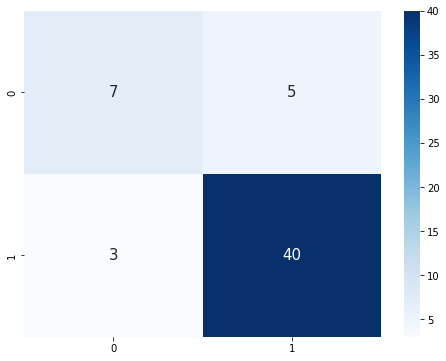

: 

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test,model2.predict(X_test)),annot=True, 
                 annot_kws={'size':15,'ha':'center','va':'center'}, 
                cmap='Blues')

In [ ]:
from sklearn.metrics import classification_report

: 

In [ ]:
print(classification_report(y_test, model2.predict(X_test)))

              precision    recall  f1-score   support

           0       0.70      0.58      0.64        12
           1       0.89      0.93      0.91        43

    accuracy                           0.85        55
   macro avg       0.79      0.76      0.77        55
weighted avg       0.85      0.85      0.85        55



: 

In [ ]:
num_pipeline=make_pipeline(StandardScaler())
cat_pipeline=make_pipeline(OneHotEncoder())
transformer=make_column_transformer((num_pipeline,selected_quanti_var),(cat_pipeline,selected_quali_var))
model3=make_pipeline(transformer,DecisionTreeClassifier(random_state=5))
param={'decisiontreeclassifier__criterion':['gini', 'entropy'],
       'decisiontreeclassifier__max_depth':np.arange(1,15)
      }
grid=GridSearchCV(model3,param_grid=param,cv=5)

grid.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('standardscaler',
                                                                                          StandardScaler())]),
                                                                         ['Floor '
                                                                          'Space',
                                                                          'Window',
                                                                          'Clearance '
                                                                          'space',
                                                                          'Competition '
                                                                          'score']),
                    

: 

In [ ]:
model33=grid.best_estimator_
model33.score(X_test,y_test)

0.7636363636363637

: 

In [ ]:
model3

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Floor Space', 'Window',
                                                   'Clearance space',
                                                   'Competition score']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  ['Car park', 'Location'])])),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(random_state=5))])

: 

In [ ]:
model33

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline-1',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Floor Space', 'Window',
                                                   'Clearance space',
                                                   'Competition score']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder())]),
                                                  ['Car park', 'Location'])])),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(criterion='entropy', max_depth=2,
                                        random_state=5))])

: 